In [1]:
import pandas as pd
import numpy as np
import kagglehub
import os
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV


c:\Users\aymen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("maqdadali/mental-health-risk-prediction-dataset-students")

df = pd.read_csv(os.path.join(path, "student_mental_health.csv"))
# print("Dataset shape:", df.shape)
print("Dataset columns:", df.columns)
# print(df.info())
# print(df.describe())
# print(df.isnull().sum())

Dataset columns: Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours',
       'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
       'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='str')


In [3]:
df = df.drop_duplicates()
df = df.dropna()
df = df.drop(columns=['Student_ID', 'Gender'])

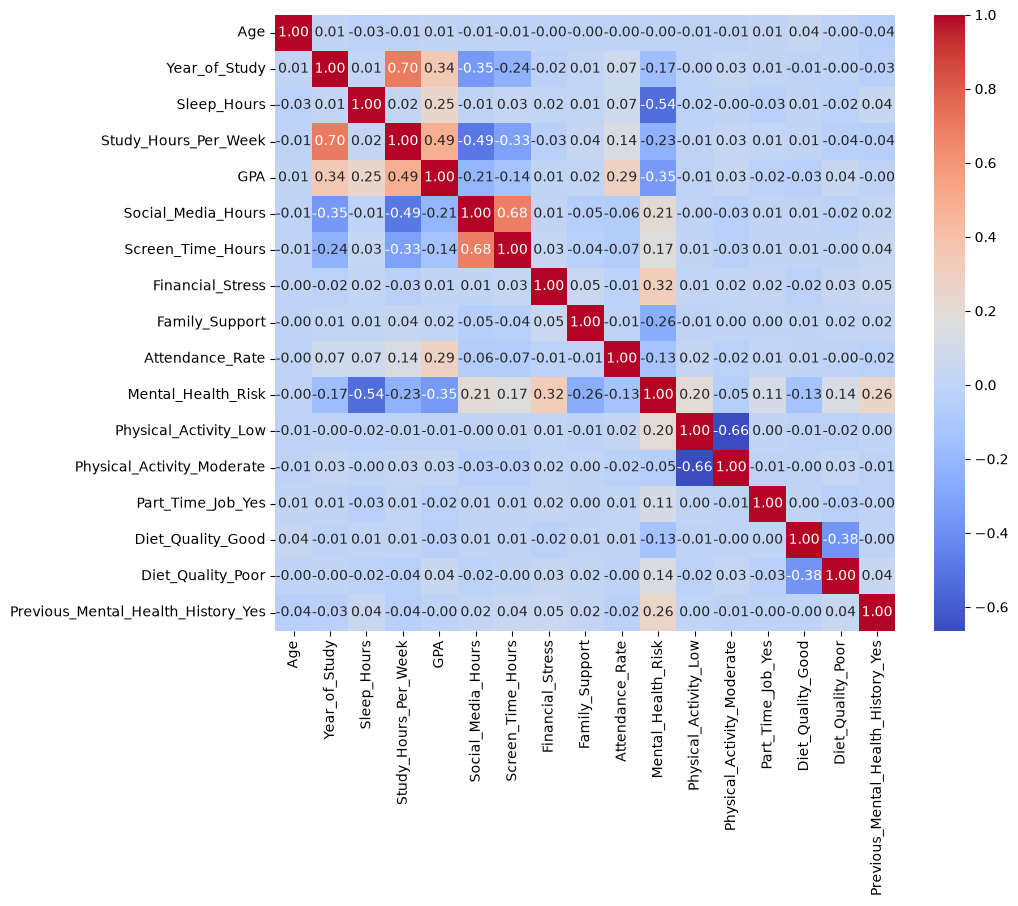

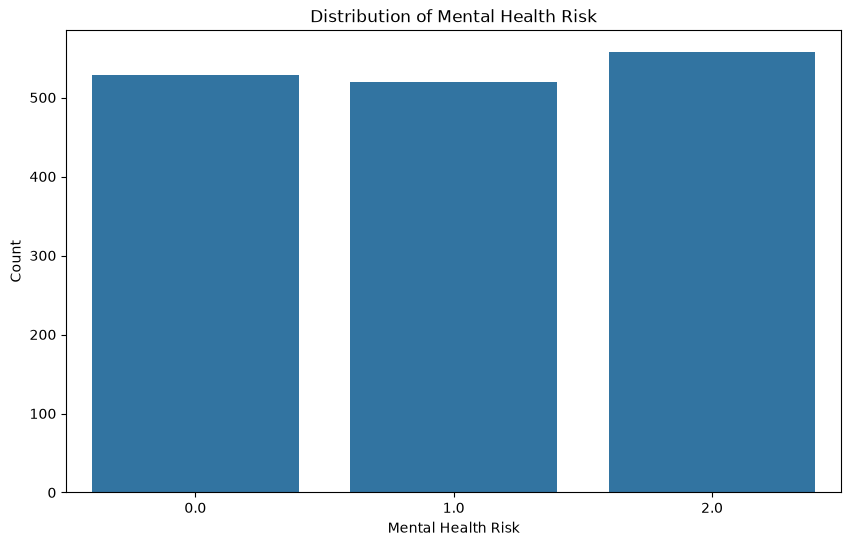

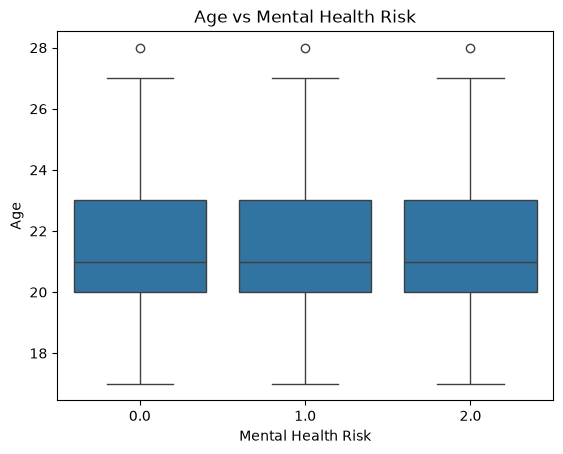

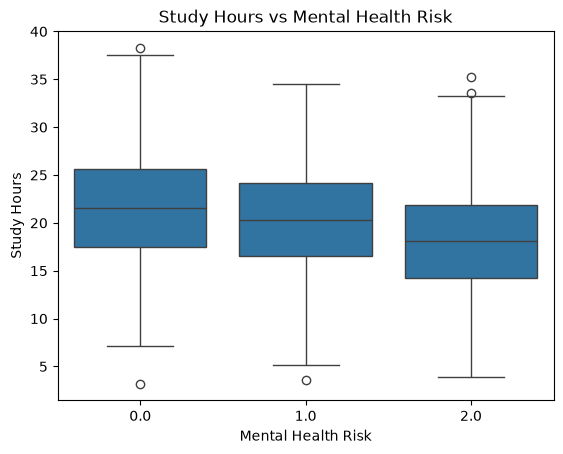

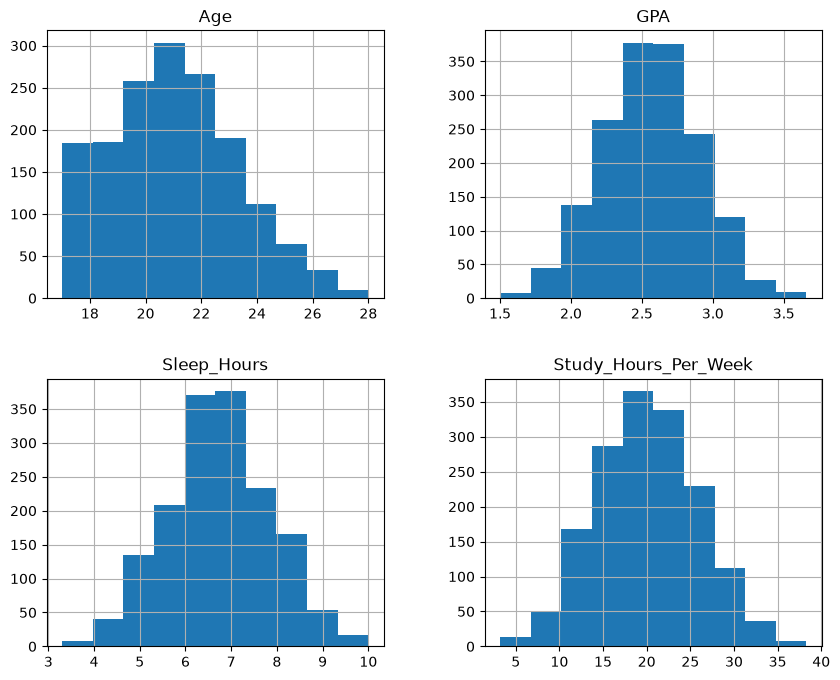

In [4]:
encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'High']])

df['Mental_Health_Risk'] = encoder.fit_transform(df[['Mental_Health_Risk']]).ravel()

df = pd.get_dummies(df, drop_first=True)

correlation_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

plt.figure(figsize=(10, 6))
sns.countplot(x='Mental_Health_Risk', data=df)
plt.title('Distribution of Mental Health Risk')
plt.xlabel('Mental Health Risk')
plt.ylabel('Count')
plt.show()

sns.boxplot(x='Mental_Health_Risk', y='Age', data=df)
plt.xlabel('Mental Health Risk')
plt.ylabel('Age')
plt.title('Age vs Mental Health Risk')
plt.show()

sns.boxplot(x='Mental_Health_Risk', y='Study_Hours_Per_Week', data=df)
plt.xlabel('Mental Health Risk')
plt.ylabel('Study Hours')
plt.title('Study Hours vs Mental Health Risk')
plt.show()

df[['Age', 'GPA', 'Sleep_Hours', 'Study_Hours_Per_Week']].hist(figsize=(10, 8))
plt.show()

In [8]:
features = ['Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Physical_Activity_Low', 'Physical_Activity_Moderate',
       'Part_Time_Job_Yes', 'Diet_Quality_Good', 'Diet_Quality_Poor', 'Previous_Mental_Health_History_Yes']
target = ["Mental_Health_Risk"]

X = df[features]
y = df['Mental_Health_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy:", model.score(X_test, y_test))

Accuracy: 0.7142857142857143
              precision    recall  f1-score   support

         0.0       0.77      0.79      0.78       101
         1.0       0.56      0.58      0.57       103
         2.0       0.82      0.76      0.79       118

    accuracy                           0.71       322
   macro avg       0.71      0.71      0.71       322
weighted avg       0.72      0.71      0.72       322

[[80 20  1]
 [24 60 19]
 [ 0 28 90]]
Train accuracy: 0.7344236760124611
Test accuracy: 0.7142857142857143


c:\Users\aymen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
